# Model XBGBoost na danych bankowych

Celem jest zbudowanie modelu klasyfikacyjnego XGBoost do przewidywania, czy klient zdecyduje się na lokatę terminową, na podstawie cech demograficznych i informacji o kontakcie marketingowym.

Zacznijmy od wczytania danych i zapoznania się z ich strukturą.

In [2]:
import pandas as pd

dane = pd.read_csv("C:/Users/olako/OneDrive/Pulpit/bankowość/dane_list2.csv", delimiter=';', skiprows=0)
print(dane)

       age           job   marital  education default  balance housing loan  \
0       58    management   married   tertiary      no     2143     yes   no   
1       44    technician    single  secondary      no       29     yes   no   
2       33  entrepreneur   married  secondary      no        2     yes  yes   
3       47   blue-collar   married    unknown      no     1506     yes   no   
4       33       unknown    single    unknown      no        1      no   no   
...    ...           ...       ...        ...     ...      ...     ...  ...   
45206   51    technician   married   tertiary      no      825      no   no   
45207   71       retired  divorced    primary      no     1729      no   no   
45208   72       retired   married  secondary      no     5715      no   no   
45209   57   blue-collar   married  secondary      no      668      no   no   
45210   37  entrepreneur   married  secondary      no     2971      no   no   

         contact  day month  duration  campaign  pd

In [3]:
dane.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


W dostępnych danych można rozróżnić: informacje o kliencie (kolumny 0-7), informacje o ostatnim kontakcie kampanii marketingowej (kolumny 8-15) oraz zmienną wyjściową y, która określa, czy klient zdecydował się na subskrypcje lokaty terminowej. 

Dostępne dane dotyczą prowadzonych telefonicznie kampanii marketingowych portugalskiej instytucji bankowej. W ramach kontaktu z jednym klientem często wykonywano więcej niż jeden telefon. Liczba rekordów wynosi 45 211. Można wyróżnić 16 atrybutów oraz zmienną wyjściową y.

Opis atrybutów zmiennych wejściowych:

0. age – wiek (numeryczna), 
1. job – rodzaj pracy (kategoryczna: "admin.", "unknown", "unemployed", "management", 
"housemaid", "entrepreneur", "student", "blue-collar", "self-employed", "retired", 
"technician", "services"), 
2. marital – stan cywilny (kategoryczna: "married", "divorced", "single"), 
3. education – poziom wykształcenia (kategoryczna: "unknown", "secondary", "primary", 
"tertiary"), 
4. default – czy klient ma zaległości w spłacie kredytu? (binarna: "yes", "no"), 
5. balance – średnie roczne saldo na koncie klienta (w euro) (numeryczna), 
6. housing – czy klient ma kredyt hipoteczny? (binarna: "yes", "no"), 
7. loan – czy klient ma kredyt gotówkowy? (binarna: "yes", "no"),
8. contact – typ komunikacji (kategoryczna: "unknown", "telephone", "cellular"), 
9. day – dzień ostatniego kontaktu w miesiącu (numeryczna), 
10. month – miesiąc ostatniego kontaktu (kategoryczna: "jan", "feb", "mar", ..., "nov", "dec"), 
11. duration – czas trwania ostatniego kontaktu (w sekundach) (numeryczna),
12. campaign – liczba kontaktów wykonanych w tej kampanii dla danego klienta (numeryczna, 
obejmuje ostatni kontakt), 
13. pdays – liczba dni od ostatniego kontaktu klienta w poprzedniej kampanii (numeryczna; -1 oznacza, że klient nie był wcześniej kontaktowany), 
14. previous – liczba kontaktów wykonanych przed tą kampanią dla danego klienta (numeryczna), 
15. poutcome – wynik poprzedniej kampanii marketingowej (kategoryczna: "unknown", "other", 
"failure", "success").


### Przygotowanie danych
W ramach przygotowania danych tworze ich kopie, żeby nie nadpisywać wejściowej ramki danych. Dodaje unikatowy numer indeksu, pozwalający na ewentualne odwołanie się do konkretnego klienta. Ręcznie zmieniam wartości w kolumnie y na wartości binarne, gdzie 0 oznacza, że klient nie zdecydował się na subskrypcje lokaty terminowej i 1 w przeciwnym przypadku. Pozostałe dane kategoryczne zmieniam na wartości numeryczne w pętli za pomocą encodera.

In [4]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# przygotowanie kopii danych
dane2 = dane.copy()

# dodanie numeru indeksu
dane2 = dane2.reset_index()
dane2 = dane2.rename(columns={'index': 'custumer_id'})

# zmiana kolumny y na wartosci binarne (1 = yes, 0 = no)
dic_y = {'no': 0, 'yes': 1}
dane2.y.replace(dic_y)

# zmiana danych kategorycznych na wartosci numeryczne
categories_encoded = {}
for col in dane2.select_dtypes(include='object').columns:
    encoder = LabelEncoder()
    dane2[col] = encoder.fit_transform(dane2[col])
    categories_encoded[col] = encoder       # zachowuje informacje o tym, ktore kategorie sa oznaczone jaka wartoscia liczbowa

dane2.head()

C:\Users\olako\AppData\Local\Temp\ipykernel_29928\3956731101.py:13: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  dane2.y.replace(dic_y)


,custumer_id,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,0,58,4,1,2,0,2143,1,0,2,5,8,261,1,-1,0,3,0
1,1,44,9,2,1,0,29,1,0,2,5,8,151,1,-1,0,3,0
2,2,33,2,1,1,0,2,1,1,2,5,8,76,1,-1,0,3,0
3,3,47,1,1,3,0,1506,1,0,2,5,8,92,1,-1,0,3,0
4,4,33,11,2,3,0,1,0,0,2,5,8,198,1,-1,0,3,0


Do przygotowania modelu rozdzielam dane na zbiór testowy i treningowy w proporcji 80:20.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(dane2[[i for i in dane.columns if i not in ['y', 'customer_id']]], dane2.y, 
                                                    test_size=0.2, random_state=20)


### Eksploracyjna analiza danych
Przyjrzyjmy się na początku zmiennym w każdej z kolumn na danych treningowych.




In [6]:
X_train.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome
31214,37,9,1,2,0,549,0,0,0,2,7,239,1,-1,0,3
12151,33,0,1,1,0,-111,1,1,2,20,6,12,3,-1,0,3
19014,59,5,1,1,0,12438,0,0,0,5,1,91,1,-1,0,3
6377,45,2,1,0,0,-100,1,0,2,27,8,240,6,-1,0,3
33726,30,8,2,0,0,1527,0,0,1,22,0,94,7,-1,0,3


Możemy zobaczyć, jakie kategorie kryją się pod nowymi etykietami numerycznymi dla kolumn ze zmiennymi kategorycznymi.

In [7]:
for col, encod in categories_encoded.items():
    mapping = { category: int(code) 
                for code, category in enumerate(encod.classes_) }
    inverse_mapping = { int(code): category 
                        for code, category in enumerate(encod.classes_) }
    print("Kategoria → Etykieta")
    print(f"\nKolumna: {col}")
    print(mapping)

Kategoria → Etykieta

Kolumna: job
{'admin.': 0, 'blue-collar': 1, 'entrepreneur': 2, 'housemaid': 3, 'management': 4, 'retired': 5, 'self-employed': 6, 'services': 7, 'student': 8, 'technician': 9, 'unemployed': 10, 'unknown': 11}
Kategoria → Etykieta

Kolumna: marital
{'divorced': 0, 'married': 1, 'single': 2}
Kategoria → Etykieta

Kolumna: education
{'primary': 0, 'secondary': 1, 'tertiary': 2, 'unknown': 3}
Kategoria → Etykieta

Kolumna: default
{'no': 0, 'yes': 1}
Kategoria → Etykieta

Kolumna: housing
{'no': 0, 'yes': 1}
Kategoria → Etykieta

Kolumna: loan
{'no': 0, 'yes': 1}
Kategoria → Etykieta

Kolumna: contact
{'cellular': 0, 'telephone': 1, 'unknown': 2}
Kategoria → Etykieta

Kolumna: month
{'apr': 0, 'aug': 1, 'dec': 2, 'feb': 3, 'jan': 4, 'jul': 5, 'jun': 6, 'mar': 7, 'may': 8, 'nov': 9, 'oct': 10, 'sep': 11}
Kategoria → Etykieta

Kolumna: poutcome
{'failure': 0, 'other': 1, 'success': 2, 'unknown': 3}
Kategoria → Etykieta

Kolumna: y
{'no': 0, 'yes': 1}


Zacznę od sprawdzenia występowania duplicatów i wartości pustych. Poniżej widać, że nie ma ich w danych.

In [8]:
# sprawdzenie liczby zduplikowanych rekordow
print(dane2.duplicated().sum())

# sprawdzenie liczby pustych wartosci w każdej z kolumn
print(dane2.isna().sum())

0
custumer_id    0
age            0
job            0
marital        0
education      0
default        0
balance        0
housing        0
loan           0
contact        0
day            0
month          0
duration       0
campaign       0
pdays          0
previous       0
poutcome       0
y              0
dtype: int64


Możemy przyjrzyć się statystykom opisowym dla każdej ze zmiennych. Mają one znaczenie w przypadku zmiennych numerycznych, czyli dla kolumn: age, balance, duration, campaign, pdays, previous.

Można także spojrzeć na niektóre ze statystyk dla zmiennych binarnych.

In [9]:
# zmienne numeryczne zbioru treningowego
X_train[['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']].describe()

,age,balance,duration,campaign,pdays,previous
count,36168.000000,36168.000000,36168.000000,36168.000000,36168.000000,36168.000000
mean,40.947716,1365.310136,258.805187,2.759207,40.295233,0.582393
std,10.630946,3035.755412,259.943461,3.052023,100.450310,2.387158
min,18.000000,-8019.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,70.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,445.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1431.000000,319.000000,3.000000,-1.000000,0.000000
max,94.000000,98417.000000,4918.000000,51.000000,871.000000,275.000000


In [10]:
# zmienne numeryczne zbioru testowego
X_test[['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']].describe()

,age,balance,duration,campaign,pdays,previous
count,9043.000000,9043.000000,9043.000000,9043.000000,9043.000000,9043.000000
mean,40.890191,1350.121088,255.594935,2.782373,39.808249,0.572045
std,10.570353,3080.679425,247.628123,3.275652,98.836715,1.932785
min,18.000000,-4057.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,81.000000,104.000000,1.000000,-1.000000,0.000000
50%,39.000000,460.000000,181.000000,2.000000,-1.000000,0.000000
75%,48.000000,1413.500000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,3366.000000,63.000000,854.000000,51.000000


In [11]:
# zmienne numeryczne zbioru treningowego
X_train[['default', 'housing', 'loan']].describe()[0:3]

,default,housing,loan
count,36168.000000,36168.000000,36168.000000
mean,0.018663,0.556929,0.161330
std,0.135333,0.496755,0.367841


In [12]:
# zmienne numeryczne zbioru testowego
X_test[['default', 'housing', 'loan']].describe()[0:3]

,default,housing,loan
count,9043.000000,9043.000000,9043.000000
mean,0.015482,0.551476,0.155811
std,0.123465,0.497371,0.362696


Można odczytać, że większość zmiennych przyjmuje podobne wartości dla danych treningowych i testowych. W szczególności średnia i odczylenie standardowe, które są w mniejszym stopniu narażone na wpływ wartości odstających.

Możemy także porównać rozkłady zbioru testowego i treningowego na wykresach - histogramach i boxplotach (dla zmiennych numerycznych) oraz barplotach (dla zmiennych kategorycznych). Z wykresów widać, że faktycznie rozkłady na obu zbiorach mają podobne rozkłady. Osiągane wartości na histogramach i barplotach są przeskalowane przez 1/4 - ze względu na proporcje przy podziale danych na zbiory testowy i treningowy. Boxploty mają bardzo zbliżony wygląd.

In [13]:
import plotly.graph_objects as go
import plotly.io as pio

#pio.renderers.default = 'notebook_connected'
#include_plotyjs=True

def plot_histograms(X_train, X_test, columns):
    for col in columns:
        fig = go.Figure()

        fig.add_trace(go.Histogram(
            x=X_train[col],
            name='Train',
            opacity=0.7,
            marker_color='skyblue',
            nbinsx=60
        ))

        fig.add_trace(go.Histogram(
            x=X_test[col],
            name='Test',
            opacity=0.6,
            marker_color='lightgreen',
            nbinsx=60
        ))

        fig.update_layout(
            title=f'Distribution of {col} in Train vs Test',
            xaxis_title=col,
            yaxis_title='count',
            barmode='overlay',
            template='plotly_white',
            width=800,
            height=500,
            legend=dict(x=0.8, y=0.95)
        )

        pio.show(fig)


def plot_barplots(X_train, X_test, columns):
    for col in columns:
        train_counts = X_train[col].value_counts().sort_index()
        test_counts = X_test[col].value_counts().sort_index()
        categories = sorted(set(train_counts.index).union(set(test_counts.index)))

        fig = go.Figure()

        fig.add_trace(go.Bar(
            x=categories,
            y=[train_counts.get(cat, 0) for cat in categories],
            name='Train',
            marker_color='skyblue',
            opacity=0.7
        ))

        fig.add_trace(go.Bar(
            x=categories,
            y=[test_counts.get(cat, 0) for cat in categories],
            name='Test',
            marker_color='lightgreen',
            opacity=0.6
        ))

        fig.update_layout(
            title=f'Barplot of {col} in Train vs Test',
            xaxis_title=col,
            yaxis_title='count',
            barmode='overlay',
            template='plotly_white',
            width=800,
            height=500,
            legend=dict(x=0.8, y=0.95)
        )

        pio.show(fig)



def plot_boxplots(X_train, X_test, columns):
    for col in columns:
        fig = go.Figure()

        fig.add_trace(go.Box(
            y=X_train[col],
            name='Train',
            boxpoints='outliers',
            marker_color='skyblue'
        ))

        fig.add_trace(go.Box(
            y=X_test[col],
            name='Test',
            boxpoints='outliers',
            marker_color='lightgreen'
        ))

        fig.update_layout(
            title=f'Boxplot of {col} in Train vs Test',
            yaxis_title=col,
            template='plotly_white',
            width=700,
            height=500
        )

        pio.show(fig)

In [14]:
# histogramy (zmienne numeryczne)
plot_histograms(X_train, X_test, ['age', 'balance', 'duration', 'campaign', 'pdays', 'previous'])

# boxploty (zmienne numeryczne)
plot_boxplots(X_train, X_test, ['age', 'balance', 'duration', 'campaign', 'pdays', 'previous'])

# barploty (zmienne kategoryczne)
plot_barplots(X_train, X_test, ['job', 'marital', 'education', 'contact', 'poutcome'])

![](./wykresy_2/1.1)
![](./wykresy_2/1.2)
![](./wykresy_2/1.3)
![](./wykresy_2/1.4)
![](./wykresy_2/1.5)
![](./wykresy_2/1.6)
![](./wykresy_2/1.7)
![](./wykresy_2/1.8)
![](./wykresy_2/1.9)
![](./wykresy_2/1.10)
![](./wykresy_2/1.11)
![](./wykresy_2/1.12)
![](./wykresy_2/1.13)
![](./wykresy_2/1.14)
![](./wykresy_2/1.15)
![](./wykresy_2/1.16)
![](./wykresy_2/1.17)

Przyjrzyjmy się korelacjom między danymi. Sprawdzimy w tym celu dane względem korelacji Pearsona i Spearmana.

Przyjnuję, że dopuszczalne są korelacje <= 0.9. Zatem dopuszczam wartości pokolorowane na zielono i pomarańczowo.

In [15]:
corr_p = X_train.corr(method='pearson')
corr_s = X_train.corr(method='spearman')

In [16]:
def color(value):
    if abs(value) <= 0.5:
        color =  'green'
    elif abs(value) <= 0.9:
        color = 'orange'
    elif abs(value) > 0.9:
        color = 'red'
    else:
        color = 'blue'
    return f'color: {color}'.format(color)

corr_p.style.applymap(color)

C:\Users\olako\AppData\Local\Temp\ipykernel_29928\3373804368.py:12: FutureWarning:

Styler.applymap has been deprecated. Use Styler.map instead.



,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome
age,1.000000,-0.022398,-0.402608,-0.112063,-0.016214,0.095448,-0.188149,-0.016219,0.024410,-0.007461,-0.043812,-0.003509,0.006076,-0.025933,-0.001685,0.009304
job,-0.022398,1.000000,0.062879,0.169080,-0.007769,0.017941,-0.124302,-0.031109,-0.087076,0.026063,-0.094220,0.002920,0.004171,-0.025868,-0.000883,0.011640
marital,-0.402608,0.062879,1.000000,0.110094,-0.007999,0.001850,-0.019072,-0.044555,-0.041484,-0.007639,-0.005455,0.012592,-0.010674,0.024290,0.016244,-0.022178
education,-0.112063,0.169080,0.110094,1.000000,-0.012626,0.067538,-0.086446,-0.048351,-0.111242,0.027271,-0.053777,0.000893,0.005985,-0.001162,0.018263,-0.018869
default,-0.016214,-0.007769,-0.007999,-0.012626,1.000000,-0.068708,-0.005728,0.079482,0.015943,0.010577,0.011928,-0.011333,0.013625,-0.030414,-0.019010,0.035131
balance,0.095448,0.017941,0.001850,0.067538,-0.068708,1.000000,-0.069107,-0.087267,-0.027694,0.002659,0.021214,0.022039,-0.013977,-0.000951,0.015007,-0.017132
housing,-0.188149,-0.124302,-0.019072,-0.086446,-0.005728,-0.069107,1.000000,0.045443,0.186477,-0.029160,0.270841,0.004071,-0.025964,0.124126,0.035904,-0.100060
loan,-0.016219,-0.031109,-0.044555,-0.048351,0.079482,-0.087267,0.045443,1.000000,-0.012068,0.010393,0.020371,-0.012150,0.010492,-0.019257,-0.009675,0.012967
contact,0.024410,-0.087076,-0.041484,-0.111242,0.015943,-0.027694,0.186477,-0.012068,1.000000,-0.027197,0.358739,-0.024645,0.020316,-0.243612,-0.142213,0.271831
day,-0.007461,0.026063,-0.007639,0.027271,0.010577,0.002659,-0.029160,0.010393,-0.027197,1.000000,-0.004701,-0.027827,0.157799,-0.094822,-0.053150,0.088208


In [17]:
corr_s.style.applymap(color)

C:\Users\olako\AppData\Local\Temp\ipykernel_29928\3977002909.py:1: FutureWarning:

Styler.applymap has been deprecated. Use Styler.map instead.



,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome
age,1.000000,-0.008415,-0.441490,-0.120417,-0.012691,0.097446,-0.157130,-0.004515,0.051353,-0.007412,-0.033834,-0.032771,0.036762,-0.019196,-0.013975,0.014914
job,-0.008415,1.000000,0.056017,0.179130,-0.005693,0.030311,-0.130718,-0.032842,-0.085756,0.026185,-0.083837,0.001128,0.013845,-0.009299,-0.002233,0.005827
marital,-0.441490,0.056017,1.000000,0.121008,-0.006478,0.021799,-0.019960,-0.045884,-0.044296,-0.008603,-0.003948,0.019541,-0.029827,0.030459,0.030465,-0.028749
education,-0.120417,0.179130,0.121008,1.000000,-0.013340,0.078169,-0.089844,-0.047798,-0.127976,0.029523,-0.047343,-0.003437,-0.001502,0.025322,0.034046,-0.030841
default,-0.012691,-0.005693,-0.006478,-0.013340,1.000000,-0.172130,-0.005728,0.079482,0.014174,0.010950,0.006028,-0.007730,0.011261,-0.038810,-0.040138,0.039346
balance,0.097446,0.030311,0.021799,0.078169,-0.172130,1.000000,-0.070612,-0.132810,-0.032992,0.003362,0.027423,0.043861,-0.031220,0.067424,0.077341,-0.072956
housing,-0.157130,-0.130718,-0.019960,-0.089844,-0.005728,-0.070612,1.000000,0.045443,0.176549,-0.028832,0.264487,0.003059,-0.036269,0.080826,0.062127,-0.074465
loan,-0.004515,-0.032842,-0.045884,-0.047798,0.079482,-0.132810,0.045443,1.000000,-0.012911,0.011093,0.001010,-0.014158,-0.000423,-0.027020,-0.028644,0.025070
contact,0.051353,-0.085756,-0.044296,-0.127976,0.014174,-0.032992,0.176549,-0.012911,1.000000,-0.027097,0.317588,-0.044898,0.008052,-0.278691,-0.277952,0.280075
day,-0.007412,0.026185,-0.008603,0.029523,0.010950,0.003362,-0.028832,0.011093,-0.027097,1.000000,0.008020,-0.056572,0.138586,-0.095954,-0.091671,0.092464


Silniejsze korelacje wykryła korelacja Spearmana. Pokazuje ona silną zależność wprost proporcjonalną między zmienną previous a pdays. Wykryła natomiast zależność przeciwnie proporcjonalną między zmiennymi poutcome i pdays oraz poutcome i previous.

Przypomnijmy, że zmienna pdays określa liczbę dni od ostatniego kontaktu klienta w poprzedniej kampanii (-1 oznacza, że klient nie był wcześniej kontaktowany), previous - liczbę kontaktów wykonanych przed tą kampanią dla danego klienta, a poutcome - wynik poprzedniej kampanii marketingowej (kategoryczna: "unknown", "other", "failure", "success").

Sugeruje to, że liczba dni od ostatniego kontaktu w poprzedniej kampanii jest powiązana z liczbą kontaktów sprzed aktualnej kampanii, co jest zgodne z intuicją.
Wynik poprzedniej kampanii jest natomiast przeciwnie proporcjonalny zarówno do liczby dni od ostatniego kontaktu w poprzedniej kampanii, jak i z liczbą kontaktów wykonanych przed tą kampanią. Może to oznaczać, że kontakty telefoniczne z klientami w poprzedniej kampanii raczej zniechęcały ich do subskrypcji lokaty terminowej.

Być może jednak sturuktura kategorii zmiennej poutcome zaburza wyniki.

In [18]:
# *metoda tuckeya: 
# |QR = Q3 - Q1
# ... < Q1 - 1.5 |QR & Q3 + 1.5 |QR < ... 

def tuckey_var(df, column):
    
    Q1 = df[column].quantile(0.25) 
    Q3 = df[column].quantile(0.75)  
    IQR = Q3 - Q1                  
    
    lower_bound = Q1 - 1.5 * IQR     
    upper_bound = Q3 + 1.5 * IQR     
    
    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    num_outliers = outliers.shape[0]  
    total_values = df[column].count()  
    
    return {
        "Variable": column,
        "Unique Values": df[column].nunique(),
        "Number of outliers": num_outliers,
        "Percentage of outliers": round((num_outliers / total_values) * 100, 2) if total_values > 0 else 0
    }


tuckey_analysis = pd.DataFrame(columns=["Variable", "Unique Values", "Number of outliers", "Percentage of outliers"])

for ft in dane2.select_dtypes(include='number'):
    new_row = pd.DataFrame([tuckey_var(dane2, ft)])  # Uwaga tutaj!
    tuckey_analysis = pd.concat([tuckey_analysis, new_row], ignore_index=True)

print(tuckey_analysis)

       Variable Unique Values Number of outliers  Percentage of outliers
0   custumer_id         45211                  0                    0.00
1           age            77                487                    1.08
2           job            12                  0                    0.00
3       marital             3                  0                    0.00
4     education             4                  0                    0.00
5       default             2                815                    1.80
6       balance          7168               4729                   10.46
7       housing             2                  0                    0.00
8          loan             2               7244                   16.02
9       contact             3                  0                    0.00
10          day            31                  0                    0.00
11        month            12                  0                    0.00
12     duration          1573               3235   

C:\Users\olako\AppData\Local\Temp\ipykernel_29928\3115673609.py:30: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.



Poniżej zebrane są również wykresy zmiennych (histogramy i barploty) z przedstawioną zależnością między zmienną objaśnianą. 

In [19]:
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio

def make_ratio_barplots_pio(X_train, y_train):
    # przygotowanie dlugiej tabeli
    X_train_cat_long_list = []
    for col in X_train.columns:
        temp = X_train[[col]].copy()
        temp["y"] = y_train

        if col in ["age", "duration", "balance", "campaign", "day"]:
            temp["bin"] = pd.qcut(temp[col], q=5, duplicates="drop")
        elif col == "pdays":
            temp["bin"] = temp[col].apply(lambda x: "-1" if x == -1 else ">-1")
        elif col == "previous":
            temp["bin"] = temp[col].apply(lambda x: "0" if x == 0 else ">0")
        else:
            temp["bin"] = temp[col]

        grouped = (
            temp.groupby('bin')
                .agg(count=("y", "size"), pos=("y", "sum"))
                .reset_index()
        )
        grouped["variable"] = col
        grouped["ratio"] = grouped["pos"] / grouped["count"]
        grouped["bin_str"] = grouped["bin"].astype(str)
        X_train_cat_long_list.append(grouped)

    df_long = pd.concat(X_train_cat_long_list, ignore_index=True)

    # parametry subplotow
    vars_ = df_long["variable"].unique()
    n_cols = 4
    n_rows = -(-len(vars_) // n_cols)

    fig = make_subplots(
        rows=n_rows, cols=n_cols,
        subplot_titles=vars_,
        specs=[[{"secondary_y": True}]*n_cols for _ in range(n_rows)],
        horizontal_spacing=0.15,
        vertical_spacing=0.15
    )

    # dodawanie sladow
    for idx, var in enumerate(vars_):
        row = idx // n_cols + 1
        col = idx % n_cols + 1
        d = df_long[df_long["variable"] == var]

        fig.add_trace(
            go.Bar(x=d["bin_str"], y=d["count"], name="Count",
                   marker_color="skyblue", showlegend=(idx==0)),
            row=row, col=col, secondary_y=False
        )
        fig.add_trace(
            go.Scatter(x=d["bin_str"], y=d["ratio"], name="Ratio of y=1",
                       mode="markers", marker=dict(color="orange", size=8),
                       showlegend=(idx==0)),
            row=row, col=col, secondary_y=True
        )
        fig.update_xaxes(tickangle=45, row=row, col=col)
        fig.update_yaxes(title_text="Count", secondary_y=False, row=row, col=col)
        fig.update_yaxes(title_text="Ratio", secondary_y=True, row=row, col=col)

    # poprawiony layout
    fig.update_layout(
        title_text="Count & Success Ratio per Category",
        template="plotly_white",
        height=350 * n_rows,
        width=1400,
        margin=dict(l=60, r=60, t=120, b=60),
        legend=dict(
            x=1.03, y=1.0,
            bgcolor='rgba(255,255,255,0)',
            bordercolor='black', borderwidth=1
        )
    )

    pio.show(fig)



make_ratio_barplots_pio(X_train, y_train)

C:\Users\olako\AppData\Local\Temp\ipykernel_29928\512925381.py:23: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

C:\Users\olako\AppData\Local\Temp\ipykernel_29928\512925381.py:23: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

C:\Users\olako\AppData\Local\Temp\ipykernel_29928\512925381.py:23: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

C:\Users\olako\AppData\Local\Temp\ipykernel_29928\512925381.py:23: FutureWarning:

Th

![](./wykresy_2/2.1)

### Budowa modelu XGBoost



Budujemy pierwszy model, który przyjmuje wszystkie zmienne.

In [20]:
import xgboost as xgb
from sklearn.metrics import roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc

model1 = xgb.XGBClassifier()
model1.fit(X_train, y_train)

pd.Series(model1.predict_proba(X_train)[:, 1])

0        0.832232
1        0.000108
2        0.018493
3        0.000259
4        0.026432
           ...   
36163    0.638618
36164    0.001465
36165    0.579867
36166    0.000020
36167    0.324994
Length: 36168, dtype: float32

In [21]:
print(model1.n_classes_)        # liczba klas zastosowanych w modelu
print(model1.n_estimators)      # liczba zbudowanych estymatorow (drzew, iteracji boostingowych) w modelu
print(model1.n_features_in_)    # liczba wykorzystywanych zmiennych

2
None
16


Sprawdzamy miarę GINI dla tego modelu. Przyjmuję ją jako miarę, względem której będę porównywać między sobą wszystkie zbudowane modele.

Dla danych bankowych GINI > 0.6 jest już dobrym wynikiem.

In [22]:
# miara GINI = 2 * AUC - 1
def gini(true_val, predicted_val):
    return 2 * roc_auc_score(true_val, predicted_val) - 1

gini(true_val=y_train, predicted_val=model1.predict_proba(X_train)[:, 1])

0.9610950570719541

In [23]:
gini(true_val=y_test, predicted_val=model1.predict_proba(X_test)[:, 1])

0.8666384290521569

Duża różnica między wartością GINI dla zbiorów train i test może świadczyć o nadmiernym dopasowaniu modelu do danych treningowych. Chcemy znaleźć model, dla którego ta różnica nie będzie aż tak duża.

[[31485   441]
 [ 1172  3070]]


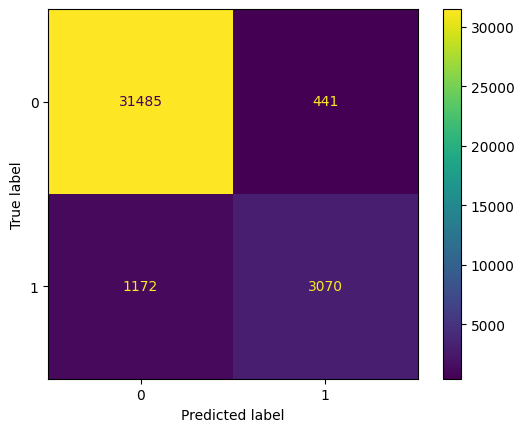

In [24]:
# macierz dla pomylek (np. dla cut-off na poziomie 50%)
pred_cutoff_50 = pd.Series(model1.predict_proba(X_train)[:, 1]).apply(lambda x: 1 if x>0.5 else 0)
cm = confusion_matrix(y_true=y_train, y_pred=pred_cutoff_50)
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model1.classes_)
disp.plot()

Poniższe wykresy ROC Curve dla zbioru treningowego i testowego również świadczą o przeuczeniu modelu.

In [25]:
def roc_curve_plot(y_true, y_score, pos_label=1, title='ROC Curve'):
    # ROC curve and AUC (area under the curve)
    fpr, tpr, _ = roc_curve(y_true, y_score, pos_label=pos_label)
    roc_auc = auc(fpr, tpr)

    # build figure
    fig = go.Figure()

    # ROC curve trace
    fig.add_trace(go.Scatter(
        x=fpr,
        y=tpr,
        mode='lines',
        line=dict(color='darkorange', width=2),
        name=f'ROC curve (AUC = {roc_auc:.3f})'
    ))

    # random guess line
    fig.add_trace(go.Scatter(
        x=[0, 1],
        y=[0, 1],
        mode='lines',
        line=dict(color='navy', width=1, dash='dash'),
        name='Random guess'
    ))

    # layout
    fig.update_layout(
        title=title,
        xaxis_title='False Positive Rate',
        yaxis_title='True Positive Rate',
        xaxis=dict(range=[0,1]),
        yaxis=dict(range=[0,1.05]),
        template='plotly_white',
        width=700,
        height=500,
        legend=dict(x=0.7, y=0.1)
    )

    pio.show(fig)


roc_curve_plot(y_train, model1.predict_proba(X_train)[:, 1])
roc_curve_plot(y_test, model1.predict_proba(X_test)[:, 1])

![](./wykresy_2/3.1)
![](./wykresy_2/3.2)

Przyjmuję za miarę jakości zmiennych miarę GAIN i sprawdzam wyniki dla pierwszego modelu.

In [26]:
model1.feature_importances_ # znormalizowane wartosci GAIN - najwazniejsze

array([0.03029242, 0.0190703 , 0.02494561, 0.02472928, 0.02111548,
       0.02098534, 0.12501979, 0.05218096, 0.12728852, 0.03034477,
       0.06649695, 0.12895273, 0.02695749, 0.06062802, 0.02287758,
       0.21811482], dtype=float32)

Tworzę tabelę, w której będę dopisywać kolejne modele i porównywać je między sobą. Dorzucam do niej model1.

In [27]:
def model_summary(model, name, description, X_train, X_test, y_train, y_test):
    y_train_score = model.predict_proba(X_train)[:, 1]
    y_test_score  = model.predict_proba(X_test)[:, 1]

    gini_train = gini(y_train, y_train_score)
    gini_test  = gini(y_test,  y_test_score)

    summary = pd.DataFrame([{
        'Nazwa modelu':     name,
        'Opis':             description,
        'Liczba zmiennych': X_train.shape[1],
        'Gini TRAIN':       round(gini_train, 4),
        'Gini TEST':        round(gini_test, 4)
    }])

    return summary


In [28]:
model_results = model_summary(model1, 'model1', 'model na domyslnych hiperparametrach', X_train, X_test, y_train, y_test)
model_results

,Nazwa modelu,Opis,Liczba zmiennych,Gini TRAIN,Gini TEST
0,model1,model na domyslnych hiperparametrach,16,0.9611,0.8666


Ustalam zmienne dummy.

In [29]:
dane3 = pd.get_dummies(dane[[i for i in dane.columns if i != 'y']])
dane3.head()

,age,balance,day,duration,campaign,pdays,previous,job_admin.,job_blue-collar,job_entrepreneur,...,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown
0,58,2143,5,261,1,-1,0,False,False,False,...,False,False,True,False,False,False,False,False,False,True
1,44,29,5,151,1,-1,0,False,False,False,...,False,False,True,False,False,False,False,False,False,True
2,33,2,5,76,1,-1,0,False,False,True,...,False,False,True,False,False,False,False,False,False,True
3,47,1506,5,92,1,-1,0,False,True,False,...,False,False,True,False,False,False,False,False,False,True
4,33,1,5,198,1,-1,0,False,False,False,...,False,False,True,False,False,False,False,False,False,True


In [30]:
dane3 = dane3.drop(columns= ['job_admin.', 'marital_divorced', 'education_primary', 'default_no', 'loan_no', 'contact_cellular', 'month_apr', 'poutcome_failure'])
dane3.head() # poprawic

,age,balance,day,duration,campaign,pdays,previous,job_blue-collar,job_entrepreneur,job_housemaid,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
0,58,2143,5,261,1,-1,0,False,False,False,...,False,False,False,True,False,False,False,False,False,True
1,44,29,5,151,1,-1,0,False,False,False,...,False,False,False,True,False,False,False,False,False,True
2,33,2,5,76,1,-1,0,False,True,False,...,False,False,False,True,False,False,False,False,False,True
3,47,1506,5,92,1,-1,0,True,False,False,...,False,False,False,True,False,False,False,False,False,True
4,33,1,5,198,1,-1,0,False,False,False,...,False,False,False,True,False,False,False,False,False,True


In [31]:
X_train_d = dane3.iloc[X_train.index, :]. copy()
X_test_d = dane3.iloc[X_test.index, :]. copy()

Trenuje model na zmienionych danych.

In [32]:
model2 = xgb.XGBClassifier()
model2.fit(X_train_d, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, random_state=None, ...)

In [33]:
model_results  = pd.concat([model_results,
                           model_summary(model2, 'model2', 'model na domyslnych hiperparametrach ze zmiennymi dummy', X_train_d, X_test_d, y_train, y_test)])
model_results

,Nazwa modelu,Opis,Liczba zmiennych,Gini TRAIN,Gini TEST
0,model1,model na domyslnych hiperparametrach,16,0.9611,0.8666
0,model2,model na domyslnych hiperparametrach ze zmienn...,43,0.9610,0.8757


Buduję kolejny model dla nowej, dobranej siatki hiperparametrów. Definiuję siatkę hiperparametrów i szukam  najlepszych z nich.

In [34]:
from skopt.space import Integer, Real 
from skopt import BayesSearchCV

In [35]:
model3 = model1 = xgb.XGBClassifier()

# definicja siatki parametrow
param_space = {
                'n_estimators': Integer(50, 200),
               'max_depth': Integer(3, 10),
               'min_child_weight': Integer(1, 200),
               'learning_rate': Real(0.01, 0.3, prior='log-uniform'),
               'subsample': Real(0.6,1.0),
               'colsample_bytree': Real(0.6, 1.0),
               'gamma': Real(1e-4, 10, prior='log-uniform'),
               'reg_lambda': Real(1e-4, 10, prior='log-uniform'),
               'reg_alpha': Real(1e-4, 10, prior='log-uniform')
               }

In [36]:
# Grid_SearchCV
grid_search1 = BayesSearchCV(
    estimator=model3,
    search_spaces=param_space,
    scoring='neg_mean_squared_error',
    n_iter=50,
    cv=3,
    verbose=3,
    random_state=42
)

In [37]:
grid_search1.fit(X_train, y_train)

Fitting 3 folds for each of 1 candidates, totalling 3 fits
[CV 1/3] END colsample_bytree=0.7640415835413256, gamma=0.43513970791520495, learning_rate=0.2387586688716479, max_depth=5, min_child_weight=134, n_estimators=112, reg_alpha=0.005684034097210145, reg_lambda=0.49833474816022466, subsample=0.7217853244146024;, score=-0.094 total time=   0.2s
[CV 2/3] END colsample_bytree=0.7640415835413256, gamma=0.43513970791520495, learning_rate=0.2387586688716479, max_depth=5, min_child_weight=134, n_estimators=112, reg_alpha=0.005684034097210145, reg_lambda=0.49833474816022466, subsample=0.7217853244146024;, score=-0.100 total time=   0.1s
[CV 3/3] END colsample_bytree=0.7640415835413256, gamma=0.43513970791520495, learning_rate=0.2387586688716479, max_depth=5, min_child_weight=134, n_estimators=112, reg_alpha=0.005684034097210145, reg_lambda=0.49833474816022466, subsample=0.7217853244146024;, score=-0.098 total time=   0.2s
Fitting 3 folds for each of 1 candidates, totalling 3 fits
[CV 1/3] 

BayesSearchCV(cv=3,
              estimator=XGBClassifier(base_score=None, booster=None,
                                      callbacks=None, colsample_bylevel=None,
                                      colsample_bynode=None,
                                      colsample_bytree=None, device=None,
                                      early_stopping_rounds=None,
                                      enable_categorical=False,
                                      eval_metric=None, feature_types=None,
                                      gamma=None, grow_policy=None,
                                      importance_type=None,
                                      interaction_constraints=None,
                                      learning_rate=None...
                             'min_child_weight': Integer(low=1, high=200, prior='uniform', transform='normalize'),
                             'n_estimators': Integer(low=50, high=200, prior='uniform', transform='normalize'),
                             'reg_alpha': Real(low=0.0001, high=10, prior='log-uniform', transform='normalize'),
                             'reg_lambda': Real(low=0.0001, high=10, prior='log-uniform', transform='normalize'),
                             'subsample': Real(low=0.6, high=1.0, prior='uniform', transform='normalize')},
              verbose=3)

In [38]:
y_train.value_counts()

y
0    31926
1     4242
Name: count, dtype: int64

In [39]:
grid_search1.best_estimator_.predict_proba(X_train)[:, 1]

array([0.95189977, 0.00133956, 0.02397726, ..., 0.49089798, 0.00300384,
       0.3083023 ], dtype=float32)

In [40]:
gini(predicted_val=grid_search1.best_estimator_.predict_proba(X_train)[:, 1], true_val=y_train)

0.9404476000798996

In [41]:
gini(predicted_val=grid_search1.best_estimator_.predict_proba(X_test)[:, 1], true_val=y_test)

0.8769212686572512

In [42]:
model_results  = pd.concat([model_results,
                           model_summary(grid_search1.best_estimator_, 'model3', 'model ze zoptymalizowanymi parametrami dla standardowego zbioru treningowego', X_train, X_test, y_train, y_test)])
model_results

,Nazwa modelu,Opis,Liczba zmiennych,Gini TRAIN,Gini TEST
0,model1,model na domyslnych hiperparametrach,16,0.9611,0.8666
0,model2,model na domyslnych hiperparametrach ze zmienn...,43,0.9610,0.8757
0,model3,model ze zoptymalizowanymi parametrami dla sta...,16,0.9404,0.8769


Model z dobranymi hiperparametrami wykonuje dla zmiennych dummy.

In [43]:
model4 = xgb.XGBClassifier()

In [44]:
grid_search2 = BayesSearchCV(
    estimator=model4,
    search_spaces=param_space,
    scoring='neg_mean_squared_error',
    n_iter=50,
    cv=3,
    verbose=3,
    random_state=42
)

In [45]:
grid_search2.fit(X_train_d, y_train)

Fitting 3 folds for each of 1 candidates, totalling 3 fits
[CV 1/3] END colsample_bytree=0.7640415835413256, gamma=0.43513970791520495, learning_rate=0.2387586688716479, max_depth=5, min_child_weight=134, n_estimators=112, reg_alpha=0.005684034097210145, reg_lambda=0.49833474816022466, subsample=0.7217853244146024;, score=-0.100 total time=   0.2s
[CV 2/3] END colsample_bytree=0.7640415835413256, gamma=0.43513970791520495, learning_rate=0.2387586688716479, max_depth=5, min_child_weight=134, n_estimators=112, reg_alpha=0.005684034097210145, reg_lambda=0.49833474816022466, subsample=0.7217853244146024;, score=-0.106 total time=   3.0s
[CV 3/3] END colsample_bytree=0.7640415835413256, gamma=0.43513970791520495, learning_rate=0.2387586688716479, max_depth=5, min_child_weight=134, n_estimators=112, reg_alpha=0.005684034097210145, reg_lambda=0.49833474816022466, subsample=0.7217853244146024;, score=-0.106 total time=   0.2s
Fitting 3 folds for each of 1 candidates, totalling 3 fits
[CV 1/3] 

BayesSearchCV(cv=3,
              estimator=XGBClassifier(base_score=None, booster=None,
                                      callbacks=None, colsample_bylevel=None,
                                      colsample_bynode=None,
                                      colsample_bytree=None, device=None,
                                      early_stopping_rounds=None,
                                      enable_categorical=False,
                                      eval_metric=None, feature_types=None,
                                      gamma=None, grow_policy=None,
                                      importance_type=None,
                                      interaction_constraints=None,
                                      learning_rate=None...
                             'min_child_weight': Integer(low=1, high=200, prior='uniform', transform='normalize'),
                             'n_estimators': Integer(low=50, high=200, prior='uniform', transform='normalize'),
                             'reg_alpha': Real(low=0.0001, high=10, prior='log-uniform', transform='normalize'),
                             'reg_lambda': Real(low=0.0001, high=10, prior='log-uniform', transform='normalize'),
                             'subsample': Real(low=0.6, high=1.0, prior='uniform', transform='normalize')},
              verbose=3)

In [46]:
best_params2 = grid_search2.best_params_

In [ ]:
model_results  = pd.concat([model_results,
                           model_summary(grid_search2.best_estimator_, 'model4', 'model ze zoptymalizowanymi parametrami dla zmiennych dummies', X_train_d, X_test_d, y_train, y_test)])
model_results

,Nazwa modelu,Opis,Liczba zmiennych,Gini TRAIN,Gini TEST
0,model1,model na domyslnych hiperparametrach,16,0.9611,0.8666
0,model2,model na domyslnych hiperparametrach ze zmienn...,43,0.9610,0.8757
0,model3,model ze zoptymalizowanymi parametrami dla sta...,16,0.9404,0.8769
0,model4,model ze zoptymalizowanymi parametrami dla szm...,43,0.9468,0.8816


Na podstawie tabeli wybieram model4 za najlepszy model, ponieważ wartość Gini TEST jest dla niego najlepsza. Sprawdźmy jakość tego modelu.

In [48]:
model_champion = grid_search2.best_estimator_

In [49]:
feature_import = model_champion.get_booster().get_score(importance_type='gain')
print(feature_import)

{'age': 4.2312397956848145, 'balance': 3.5998876094818115, 'day': 4.447103023529053, 'duration': 15.57925796508789, 'campaign': 4.094250202178955, 'pdays': 5.57419490814209, 'previous': 4.028714179992676, 'job_blue-collar': 4.7807207107543945, 'job_entrepreneur': 3.547654867172241, 'job_housemaid': 4.008934497833252, 'job_management': 3.1056199073791504, 'job_retired': 4.406381130218506, 'job_self-employed': 4.703103542327881, 'job_services': 3.260526418685913, 'job_student': 5.7763237953186035, 'job_technician': 3.332012176513672, 'job_unemployed': 4.094527244567871, 'job_unknown': 2.8242685794830322, 'marital_married': 3.707643747329712, 'marital_single': 3.6608757972717285, 'education_secondary': 2.985842704772949, 'education_tertiary': 3.59783673286438, 'education_unknown': 4.1790771484375, 'default_yes': 4.627212047576904, 'housing_no': 12.501779556274414, 'housing_yes': 16.27825927734375, 'loan_yes': 7.811277866363525, 'contact_telephone': 3.983799934387207, 'contact_unknown': 23

In [50]:
def plot_feature_importance(feature_names, feature_importances, title="Feature Importances"):
    df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': feature_importances
    }).sort_values('Importance', ascending=False)
    
    # ulozenie zmiennych od najistotniejszej
    fig = go.Figure(go.Bar(
        x=df['Importance'][::-1],
        y=df['Feature'][::-1],
        orientation='h',
        marker_color='blue'
    ))
    
    # layout
    fig.update_layout(
        title=title,
        xaxis_title="Feature Importance",
        yaxis_title="Features",
        template='plotly_white',
        width=800,
        height=600,
        margin=dict(l=150, r=50, t=100, b=50)
    )
    
    pio.show(fig)


feature_names = list(feature_import.keys())
feature_importances = list(feature_import.values())

plot_feature_importance(feature_names, feature_importances)
# uwaga: gain dotyczy struktury drzewa a nie danych

![](./wykresy_2/4.1)

In [51]:
from sklearn.inspection import permutation_importance

pi_results = permutation_importance(model_champion, X_train_d, y_train, n_repeats=10, random_state=0)
print(pi_results)

{'importances_mean': array([1.27598983e-02, 1.64482415e-02, 2.24535501e-02, 7.83482637e-02,
       5.97213006e-03, 8.63746959e-03, 2.25337315e-03, 1.74740102e-03,
       1.74187127e-04, 2.18425127e-04, 9.28998009e-04, 3.53904004e-04,
       4.23025879e-04, 2.29484627e-04, 2.48838752e-04, 7.54810883e-04,
       9.95355010e-05, 5.25326255e-05, 4.52057067e-03, 1.35478876e-03,
       2.00176952e-03, 2.48009290e-03, 3.26255253e-04, 1.38243751e-04,
       7.08637470e-03, 2.32249502e-04, 2.49944702e-03, 8.12873258e-04,
       1.70288653e-02, 1.45985401e-03, 3.23490378e-04, 1.50962177e-03,
       2.41097102e-03, 3.33167441e-03, 3.10218978e-03, 3.13813316e-03,
       4.78323380e-03, 2.80081840e-03, 1.83034727e-03, 1.38520239e-03,
       5.83388631e-04, 1.08466047e-02, 3.59433754e-05]), 'importances_std': array([4.83220745e-04, 4.09621624e-04, 7.31355176e-04, 9.32386208e-04,
       5.24014941e-04, 3.01155691e-04, 1.41657691e-04, 1.58251361e-04,
       1.27933370e-04, 7.15135875e-05, 1.36126229e-

In [52]:
pi_results.importances_mean

plot_feature_importance(X_train_d.columns, pi_results.importances_mean, title="Permutation Importances")

![](./wykresy_2/5.1)

In [ ]:
import shap

X_train_d_num = X_train_d.astype('float64')

explainer = shap.TreeExplainer(model_champion, data=X_train_d_num)
shap_values = explainer.shap_values(X_train_d_num)

100%|===================| 36162/36168 [18:03<00:00]        

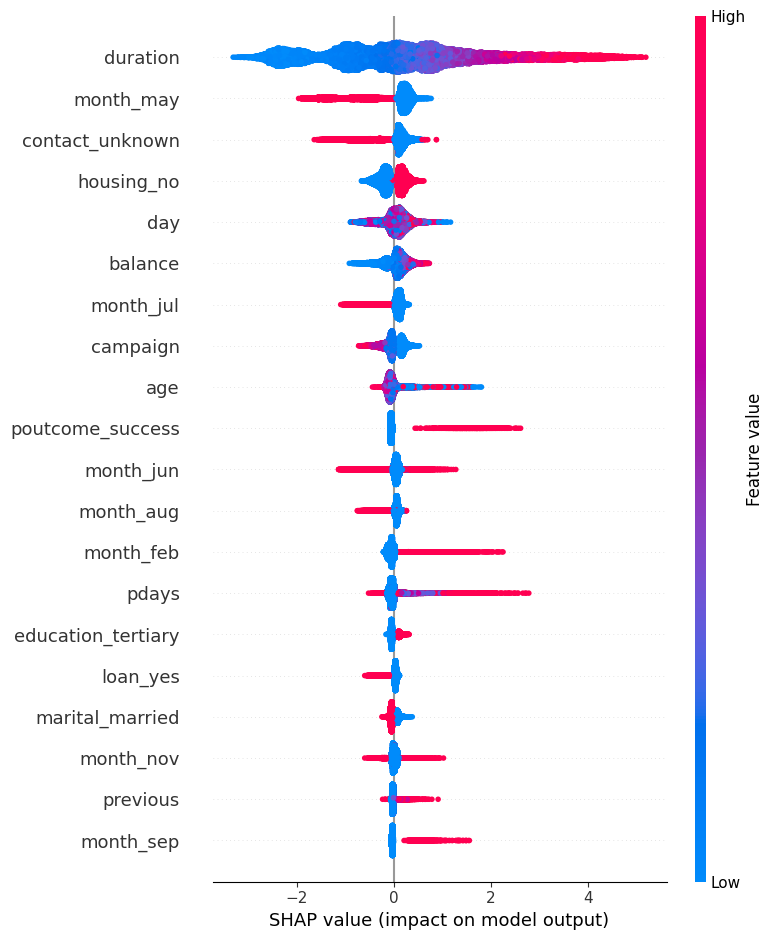

In [ ]:
shap.summary_plot(shap_values, X_train_d_num)
# interpretacja dla rodzaju zmiennych

Dla wszystkich powyższych zmiennych wartości oznaczone na czerwono wskazują na oczekiwany zysk. Przykładowo im dłuższy czas kontaktu (duration), tym wieksza szansa, ze klient weźmie produkt. Wyniki wskazują, że produkty lepiej adresować do osób posiadających kredyt hipoteczny (zmienna housing) oraz osób, które w poprzednich kampaniach brało produkty (zmianna poutcome_success).